# **Lab 5: Graphs I**
### Programmable mesh graph for automatic routing
***

### Andrés Sanchez-Toril

### Basic Commands

We are going to use the library NetworkX to create the graphs. It is not a default Python library, so you'll need to install it to use it. 

A quick way to start a graph is by creating a `Graph` object Graphand using the `get` method add_edges_from. This automatically generates the list of vertices. Since a `Graph` object is being used Graph, the library knows that edges are undirected and must be considered on both sides. For this reason, it is not necessary to add the "return" edges.

The vertices and edges of a graph can be queried using the attributes `vertices` and ` edges`, respectively. These are special object types that, if in doubt, should be converted to a list.

You can also look up the neighbors of a vertex using the neighbors graph method. This returns an iterator, so you need to use `iterator` list to convert it to a list.

In [1]:
import networkx as nx

G=nx.Graph()
G.add_edges_from([(1,2),(2,3),(3,4),(4,1),(2,4)])

print("The vertices of G are {}".format(list(G.nodes)))
print("The edges of G are {}".format(list(G.edges)))

print("The neighbors of 1 in G are {}".format(list(G.neighbors(1))))
print("The neighbors of 4 in G are {}".format(list(G.neighbors(4))))

The vertices of G are [1, 2, 3, 4]
The edges of G are [(1, 2), (1, 4), (2, 3), (2, 4), (3, 4)]
The neighbors of 1 in G are [2, 4]
The neighbors of 4 in G are [3, 1, 2]


In NetworkX, you can also add weights to edges, which can be easily done using the 'weight' method `add_weighted_edges_from`. The first two entries in each set of three correspond to the vertices, and the third to the weight. To retrieve the weight of an edge, you can read the graph as if it were first a matrix and then a dictionary using the 'weight' key `weight`.

If we want to query the edges with all their information, we have to use `edges` the method and set the parameter `data` as `True`.

In [2]:
W=nx.Graph()
W.add_weighted_edges_from([(1,2,1.1),(2,3,1.2),(3,4,1.4),(4,1,0),(2,4,1.6)])

print("The vertices of W are {}".format(list(W.nodes)))
print("The edges of W are {}".format(list(W.edges)))
print("The weight of edge (4,3) is {}".format(W[4][3]['weight']))
print("The edges of W and their weights are {}".format(list(W.edges(data=True))))

The vertices of W are [1, 2, 3, 4]
The edges of W are [(1, 2), (1, 4), (2, 3), (2, 4), (3, 4)]
The weight of edge (4,3) is 1.4
The edges of W and their weights are [(1, 2, {'weight': 1.1}), (1, 4, {'weight': 0}), (2, 3, {'weight': 1.2}), (2, 4, {'weight': 1.6}), (3, 4, {'weight': 1.4})]


As you can see in the last list, NetworkX uses a dictionary to store the weight. This is the edge data dictionary, and it can store much more general information than just the weight. Similarly, vertices also have their own data dictionary.

To use directed graphs, you must use a different type of object: 'object' `DiGraph`. Using this object tells NetworkX that the order of each edge is important, and that's how it converts them into arrows. When you use 'object' `neighbors` now, you only get the vertices to which there is an arrow from the given vertex. If you want to know the vertices to which there is an arrow from the given vertex, you have to use 'object' `predecessors`. Compare the following code with the first one we saw.

In [3]:
D = nx.DiGraph()
D.add_edges_from([(1,2),(2,3),(3,4),(4,1),(2,4)])

print("In D there is an arrow from 1 to vertices {}".format(list(D.neighbors(1))))
print("In D there is an arrow from 4 to vertices {}".format(list(D.neighbors(4))))

print("In D there is an arrow towards 1 from vertices {}".format(list(D.predecessors(1))))
print("In D there is an arrow towards 4 from vertices {}".format(list(D.predecessors(4))))

In D there is an arrow from 1 to vertices [2]
In D there is an arrow from 4 to vertices [1]
In D there is an arrow towards 1 from vertices [4]
In D there is an arrow towards 4 from vertices [3, 2]


***

### Graph Drawings

Another advantage of NetworkX is that it has utilities for drawing graphs. In the simplest case, you just need to use the drawlibrary's function and provide the graph as an argument.

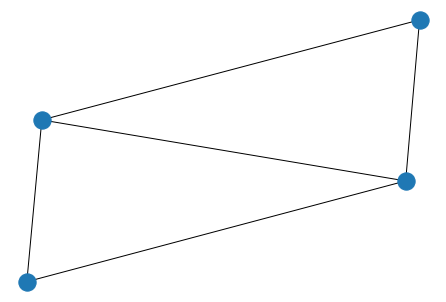

In [4]:
nx.draw(G)

Optionally, nodes can be labeled by name, colored, have their edge styles changed, and so on. A `ax` Matplotlib object can also be provided on which to draw. This allows you to use Matplotlib's full flexibility to determine sizes, titles, legends, positions, and more.

Another important factor for proper visualization is the use of layouts , which are ways of arranging the vertices. You can specify that they are arranged in a circle, aligned, in rows, etc.

To label the edges, you need to ask the library to explicitly draw the weights using `weights` draw_networkx_edge_labels. To do this, you must use the same layout both in `draw` and in this function.

Let's do some basic drawings of G,W and D that we created in the previous section.

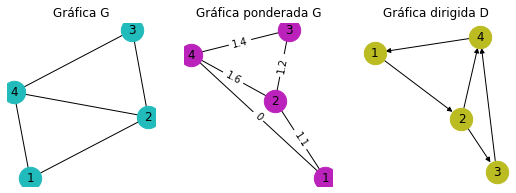

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,3)

fig.set_size_inches(9,3)

nx.draw(G,ax=axes[0],with_labels=True, node_color='#22bbbb',node_size=500)
axes[0].set_title("Gráfica G")

layout=nx.spring_layout(W)
labels2 = nx.get_edge_attributes(W,'weight')
nx.draw(W,layout,ax=axes[1],with_labels=True, node_color='#bb22bb',node_size=500)
nx.draw_networkx_edge_labels(W,layout,ax=axes[1],edge_labels=labels2)
axes[1].set_title("Gráfica ponderada G")

nx.draw(D,ax=axes[2],with_labels=True, node_color='#bbbb22',node_size=500)
axes[2].set_title("Gráfica dirigida D")

plt.show()

### Exercise 1

Do a graph that represents a Mach-Zehnder Interferometer and draw it. Use `G.add_node()` to define first all the nodes and then make the connections with `G.add_edges_from()`.

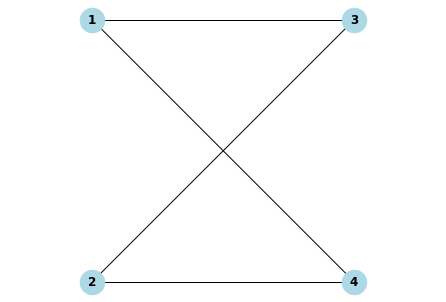

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.Graph()

# Add nodes (MZI ports) # 4 in total (Complete)
G.add_node(1)
G.add_node(2)
G.add_node(3)
G.add_node(4)

# Connections between MZI nodes (Complete)
# Conectamos las entradas (1 y 2) con las salidas (3 y 4)
G.add_edges_from([(1, 3), (1, 4), (2, 3), (2, 4)])

# Node positions (Complete)
side = 1    # length of the MZI horizontally
sep = 0.5   # Vertical separation between the two arms


pos = {
    1: (0, sep),
    2: (0, -sep),
    3: (side, sep),
    4: (side, -sep),
}

# Draw the graph (Complete)
plt.figure()
# Add line here

nx.draw(G, pos=pos, with_labels=True, node_color='lightblue', node_size=600, font_weight='bold')

plt.axis('equal')
plt.show()

### Exercise 2

Now create a tri-lattice structure function, where the input parameters are the origin position of the tri-lattice `origin_pos = (ox,oy)`.

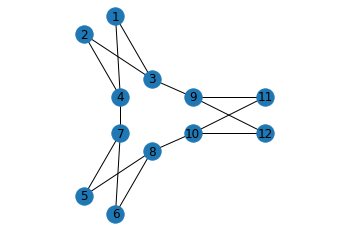

In [17]:
def tri_lattice(origin_pos):
    
    ox = origin_pos[0]
    oy = origin_pos[1]

    # Empty graph
    G = nx.Graph()

    # Add nodes (MZI ports) # 12 in total
    for i in range(1,13):
        G.add_node(i)

    # Connections between MZIs
    G.add_edges_from([(1,3),(1,4),(2,3),(2,4),(3,9),(4,7),(5,7),(5,8),(6,7),(6,8),(8,10),(9,11),(9,12),(10,11),(10,12)])
    # Node positions
    side = 1    # length of the MZI horizontally
    sep = 0.5   # Vertical separation between the two arms

    # Use trigonometry to calculate positions of the nodes
    theta  =4 * np.pi/3
    r, r2 = 1, 0.5

    pos = {
        1: (ox + r2*np.cos(np.pi/6) + r*np.cos(-theta),oy + r2*np.sin(np.pi/6) + r*np.sin(-theta)),
        2: (ox + r*np.cos(-theta), oy + r*np.sin(-theta)),
        3: (ox + r2*np.cos(np.pi/6),oy + r2*np.sin(np.pi/6)),
        4: (ox,oy),
        5: (ox + r*np.cos(theta),oy - sep + r*np.sin(theta)),
        6: (ox + r2*np.cos(-np.pi/6) + r*np.cos(theta),oy - sep + r2*np.sin(-np.pi/6) + r*np.sin(theta)),
        7: (ox,oy - sep),
        8: (ox + r2*np.cos(-np.pi/6),oy - sep + r2*np.sin(-np.pi/6)),
        9: (ox + side,oy),
        10: (ox + side,oy - sep),
        11: (ox + side*2, oy),
        12: (ox + side * 2, oy - sep),
        # Complete
    }
    
    return G, pos

origin = (0,0)
G_trilattice, pos = tri_lattice(origin)

# Draw the graph
plt.figure()
plt.axis('equal')
nx.draw(G_trilattice, with_labels=True, pos=pos)
plt.show()

### Exercise 3

Add a counter `i` to the function in order to create automatically the node numbers.

In [21]:
def tri_lattice(origin_pos, offset=0):
    ox = origin_pos[0]
    oy = origin_pos[1]

    G = nx.Graph()

    # Añadimos los 12 nodos (del 0 al 11) + el offset
    for n in range(12):
        G.add_node(offset + n)

    # Conexiones originales restando 1 a cada número (para ser 0-11) y sumando el offset
    edges = [(0,2),(0,3),(1,2),(1,3),(2,8),(3,6),(4,6),(4,7),(5,6),(5,7),(7,9),(8,10),(8,11),(9,10),(9,11)]
    G.add_edges_from([(u + offset, v + offset) for u, v in edges])

    side = 1    
    sep = 0.5   
    theta = 4 * np.pi/3
    r, r2 = 1, 0.5

    # Posiciones con el offset en las keys
    pos = {
        offset + 0: (ox + r2*np.cos(np.pi/6) + r*np.cos(-theta), oy + r2*np.sin(np.pi/6) + r*np.sin(-theta)),
        offset + 1: (ox + r*np.cos(-theta), oy + r*np.sin(-theta)),
        offset + 2: (ox + r2*np.cos(np.pi/6), oy + r2*np.sin(np.pi/6)),
        offset + 3: (ox, oy),
        offset + 4: (ox + r*np.cos(theta), oy - sep + r*np.sin(theta)),
        offset + 5: (ox + r2*np.cos(-np.pi/6) + r*np.cos(theta), oy - sep + r2*np.sin(-np.pi/6) + r*np.sin(theta)),
        offset + 6: (ox, oy - sep),
        offset + 7: (ox + r2*np.cos(-np.pi/6), oy - sep + r2*np.sin(-np.pi/6)),
        offset + 8: (ox + side, oy),
        offset + 9: (ox + side, oy - sep),
        offset + 10: (ox + side*2, oy),
        offset + 11: (ox + side * 2, oy - sep),
    }
    
    return G, pos

### Exercise 4

Create a hexagonal graph with size=(5,5), which means 5 tri-lattice rows and columns, joined between them with propper connections.

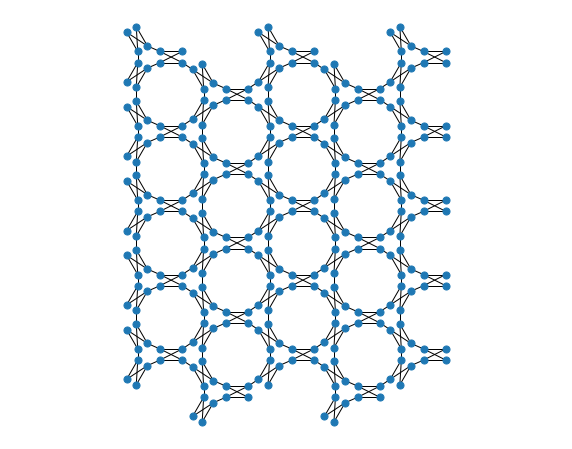

In [23]:
G_hex = nx.Graph()
pos_hex = {}

vn = 5 # number of tri-lattice rows
hn = 5 # number of tri-lattice columns

a1 = 2*np.pi/3
a2 = 4*np.pi/3
# Node positions
side = 1    # length of the MZI horizontally
sep = 0.5   # Vertical separation between the two arms
p0_y = (sep+side)*np.sin(a1) + (-sep/2)*np.cos(a1)
p1_x = (sep+side)*np.cos(a1) - (sep/2)*np.sin(a1)
p5_y = (sep+side)*np.sin(a2) + (sep/2)*np.cos(a2)
p11_x = sep + side

sep = 0.5 # linea para conectar tri-lattices
dx = (p11_x - p1_x) + sep 
dy = (p0_y - p5_y) + sep

i = 0
n_mzi = 0

for row in range(vn):
    for column in range(hn):
        if row % 2 == 0:
            origin = (row * dx, -column * dy)
        else:
            origin = (row * dx , -column * dy -(dy/2))
        # Create tri-lattice at corresponding position    
        G, pos = tri_lattice(origin, i*12)
        # Update nodes and edges of the hexagonal graph
        G_hex.add_nodes_from(G.nodes(data=True))
        G_hex.add_edges_from(G.edges(data=True))
        pos_hex.update(pos)
        
        # Connections between tri-lattices (DO NOT MODIFY)
        if column!=0:
            G_hex.add_edge((i-1)*12 + 5, i*12)
        if row!=0:
            if row%2 == 1:
                if column != hn-1:
                    G_hex.add_edge((i-hn)*12 + 11, i*12 + 1)
                    G_hex.add_edge((i-(hn-1))*12 + 10, i*12 + 4)
                if column == hn-1:
                    G_hex.add_edge((i-hn)*12 + 11, i*12 + 1)
            else: 
                if column != 0:
                    G_hex.add_edge((i-(hn+1))*12 + 11, i*12 + 1)
                    G_hex.add_edge((i-hn)*12 + 10, i*12 + 4)
                if column == 0:
                    G_hex.add_edge((i-hn)*12 + 10, i*12 + 4)

        i = i + 1
        n_mzi = n_mzi + 3

# Find external ports (nodes with less than 3 connections)
max_connections = 3        
ports = [node for node in G_hex.nodes if G_hex.degree[node] < max_connections]

# Draw the graph
plt.figure(figsize=(10,8))
plt.axis('equal')
nx.draw(G_hex, pos=pos_hex, node_size=50)
plt.show()